In [1]:
from pathlib import Path
from itertools import product
import sys

# Permite executar o notebook a partir da raiz ou da pasta notebooks.
project_root = Path.cwd().resolve()
if not (project_root / "src" / "softmax.py").is_file():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))

from dataprep import prepare_data, RAW_SIGNAL_NAMES
from softmax import SoftmaxRegression

# A padronização é ajustada apenas no treino.
dados = prepare_data(
    representation="raw", standardize=True,
    split_seed=42, validation_subject_count=4,
)
print("Amostras treino / validacao / teste:",
      len(dados.y_train), len(dados.y_validation), len(dados.y_test))
print("Sujeitos:", dados.subject_split)
print("Sinais concatenados:", RAW_SIGNAL_NAMES)
print("Atributos por amostra:", dados.X_train.shape[1], "(6 sinais x 128 valores)")
learning_rates = [0.01, 0.03, 0.1, 0.2]
l2_values = [0.0, 1e-5, 1e-4, 1e-3, 1e-2]

# Nesta etapa, mantemos fixos os critérios de parada.
max_epochs_base = 1000
tolerance_base = 1e-7
resultados_lr_l2 = []
for learning_rate, l2 in product(learning_rates, l2_values):
    modelo = SoftmaxRegression(
        learning_rate=learning_rate, l2=l2,
        max_epochs=max_epochs_base, tolerance=tolerance_base,
    ).fit(dados.X_train, dados.y_train)
    custo_validacao = modelo.loss(dados.X_validation, dados.y_validation)
    resultados_lr_l2.append({
        "learning_rate": learning_rate, "l2": l2,
        "custo_validacao": custo_validacao,
    })

# Custo = entropia cruzada + penalização L2, conforme softmax.py.
melhor_lr_l2 = min(resultados_lr_l2, key=lambda r: r["custo_validacao"])
print("Melhores hiperparâmetros (etapa 1):", melhor_lr_l2)


Amostras treino / validacao / teste: 5800 1552 2947
Sujeitos: SubjectSplit(train=(1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 19, 21, 22, 23, 27, 28, 29), validation=(17, 25, 26, 30), test=(2, 4, 9, 10, 12, 13, 18, 20, 24))
Sinais concatenados: ('total_acc_x', 'total_acc_y', 'total_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z')
Atributos por amostra: 768 (6 sinais x 128 valores)
Melhores hiperparâmetros (etapa 1): {'learning_rate': 0.01, 'l2': 0.0, 'custo_validacao': 1.0795136004348134}


In [2]:
max_epochs_values = [300, 800, 1500]
tolerance_values = [1e-5, 1e-6, 1e-7]

# Execute após o primeiro bloco: fixa o learning_rate e o L2 escolhidos.
resultados_parada = []
melhor_modelo = None
menor_custo = float("inf")
for max_epochs, tolerance in product(max_epochs_values, tolerance_values):
    modelo = SoftmaxRegression(
        learning_rate=melhor_lr_l2["learning_rate"],
        l2=melhor_lr_l2["l2"],
        max_epochs=max_epochs, tolerance=tolerance,
    ).fit(dados.X_train, dados.y_train)
    custo_validacao = modelo.loss(dados.X_validation, dados.y_validation)
    resultados_parada.append({
        "max_epochs": max_epochs, "tolerance": tolerance,
        "custo_validacao": custo_validacao,
    })
    if custo_validacao < menor_custo:
        menor_custo = custo_validacao
        melhor_modelo = modelo

melhor_parada = min(resultados_parada, key=lambda r: r["custo_validacao"])
melhores_hiperparametros = {
    "learning_rate": melhor_lr_l2["learning_rate"],
    "l2": melhor_lr_l2["l2"],
    "max_epochs": melhor_parada["max_epochs"],
    "tolerance": melhor_parada["tolerance"],
}
print("Melhores hiperparâmetros (etapa 2):", melhor_parada)
print("Configuração final:", melhores_hiperparametros)
# Busca sequencial: não garante o mínimo da grade conjunta dos quatro parâmetros.
# O conjunto de teste não é usado no ajuste nem na seleção.


Melhores hiperparâmetros (etapa 2): {'max_epochs': 300, 'tolerance': 1e-05, 'custo_validacao': 1.0642951097413307}
Configuração final: {'learning_rate': 0.01, 'l2': 0.0, 'max_epochs': 300, 'tolerance': 1e-05}


In [3]:
import json
import numpy as np
from softmax import confusion_matrix

# Hiperparâmetros escolhidos exclusivamente na validação.
# Execute as células anteriores antes desta.
X_treino_final = np.vstack((dados.X_train, dados.X_validation))
y_treino_final = np.concatenate((dados.y_train, dados.y_validation))
# Mantemos a padronização usada na seleção, ajustada apenas no treino original.
modelo_final = SoftmaxRegression(**melhores_hiperparametros)
modelo_final.fit(X_treino_final, y_treino_final)

# Teste reservado para a avaliação final, sem reajustar hiperparâmetros.
y_pred_teste = modelo_final.predict(dados.X_test)
matriz_confusao_teste = confusion_matrix(
    dados.y_test, y_pred_teste, labels=modelo_final.classes_,
)
metricas_finais = {
    "hiperparametros": melhores_hiperparametros,
    "representacao": "raw",
    "sinais": list(RAW_SIGNAL_NAMES),
    "numero_atributos": dados.X_train.shape[1],
    "divisao": "teste_oficial_uci_har",
    "split_seed": 42,
    "sujeitos_treino": list(dados.subject_split.train),
    "sujeitos_validacao": list(dados.subject_split.validation),
    "sujeitos_teste": list(dados.subject_split.test),
    "amostras_treino_selecao": len(dados.y_train),
    "amostras_validacao": len(dados.y_validation),
    "amostras_treino_final": len(y_treino_final),
    "amostras_teste": len(dados.y_test),
    "epocas_executadas": modelo_final.n_iter_,
    "convergiu_por_tolerancia": modelo_final.converged_,
    "custo_treino_final": modelo_final.loss_,
    "custo_teste": modelo_final.loss(dados.X_test, dados.y_test),
    "acuracia_teste": float(np.mean(y_pred_teste == dados.y_test)),
    "acuracia_balanceada_teste": modelo_final.score(dados.X_test, dados.y_test),
    "classes": modelo_final.classes_.tolist(),
    "matriz_confusao_teste": matriz_confusao_teste.tolist(),
}

# Salva pesos e parâmetros de padronização para reproduzir as previsões.
pasta_resultados = project_root / "results"
pasta_resultados.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    pasta_resultados / "softmax_2a_final.npz",
    weights=modelo_final.weights_, bias=modelo_final.bias_,
    classes=modelo_final.classes_,
    train_mean=dados.train_mean, train_scale=dados.train_scale,
    feature_names=np.asarray(dados.feature_names),
    loss_history=np.asarray(modelo_final.loss_history_),
    train_subjects=np.asarray(dados.subject_split.train),
    validation_subjects=np.asarray(dados.subject_split.validation),
    test_subjects=np.asarray(dados.subject_split.test),
    **melhores_hiperparametros,
)
(pasta_resultados / "softmax_2a_metricas.json").write_text(
    json.dumps(metricas_finais, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
print("SOFTMAX 2a - ACC/GYR: 6 sinais x 128 valores = 768 atributos")
print("Hiperparametros:", melhores_hiperparametros)
print(f"Treino final: {len(y_treino_final)} amostras | Teste oficial: {len(dados.y_test)} amostras")
print(f"Epocas: {modelo_final.n_iter_} | Convergiu por tolerancia: {modelo_final.converged_}")
print(f"Custo no treino: {modelo_final.loss_:.6f} | Custo no teste: {metricas_finais['custo_teste']:.6f}")
print(f"Acuracia no teste: {100 * metricas_finais['acuracia_teste']:.2f}%"
      f" | Acuracia balanceada: {100 * metricas_finais['acuracia_balanceada_teste']:.2f}%")
nomes = {1: "Caminhar", 2: "Subir escadas", 3: "Descer escadas", 4: "Sentado", 5: "Em pe", 6: "Deitado"}
acertos = np.diag(matriz_confusao_teste)
totais = matriz_confusao_teste.sum(axis=1)
print(f"Acertos totais: {acertos.sum()} / {totais.sum()}")
print(f"{'Classe real':<22} {'Acertos':>8} {'Total':>8} {'Erros':>8} {'Recall':>10}")
for classe, certo, total in zip(modelo_final.classes_, acertos, totais):
    print(f"{nomes[classe]:<22} {certo:>8d} {total:>8d} {total-certo:>8d} {100*certo/total:>9.2f}%")
print("Matriz de confusao: linhas = reais, colunas = previstas; classes 1 a 6")
print(matriz_confusao_teste)

(pasta_resultados / "softmax_2a_busca.json").write_text(
    json.dumps({"etapa_1": resultados_lr_l2, "etapa_2": resultados_parada}, indent=2) + "\n",
    encoding="utf-8",
)


SOFTMAX 2a - ACC/GYR: 6 sinais x 128 valores = 768 atributos
Hiperparametros: {'learning_rate': 0.01, 'l2': 0.0, 'max_epochs': 300, 'tolerance': 1e-05}
Treino final: 7352 amostras | Teste oficial: 2947 amostras
Epocas: 300 | Convergiu por tolerancia: False
Custo no treino: 0.925048 | Custo no teste: 1.171092
Acuracia no teste: 53.95% | Acuracia balanceada: 52.49%
Acertos totais: 1590 / 2947
Classe real             Acertos    Total    Erros     Recall
Caminhar                     71      496      425     14.31%
Subir escadas               221      471      250     46.92%
Descer escadas               94      420      326     22.38%
Sentado                     374      491      117     76.17%
Em pe                       320      532      212     60.15%
Deitado                     510      537       27     94.97%
Matriz de confusao: linhas = reais, colunas = previstas; classes 1 a 6
[[ 71 125  32  72 196   0]
 [ 85 221  46  33  86   0]
 [ 50  60  94  61 155   0]
 [  0  23   0 374  94   0]


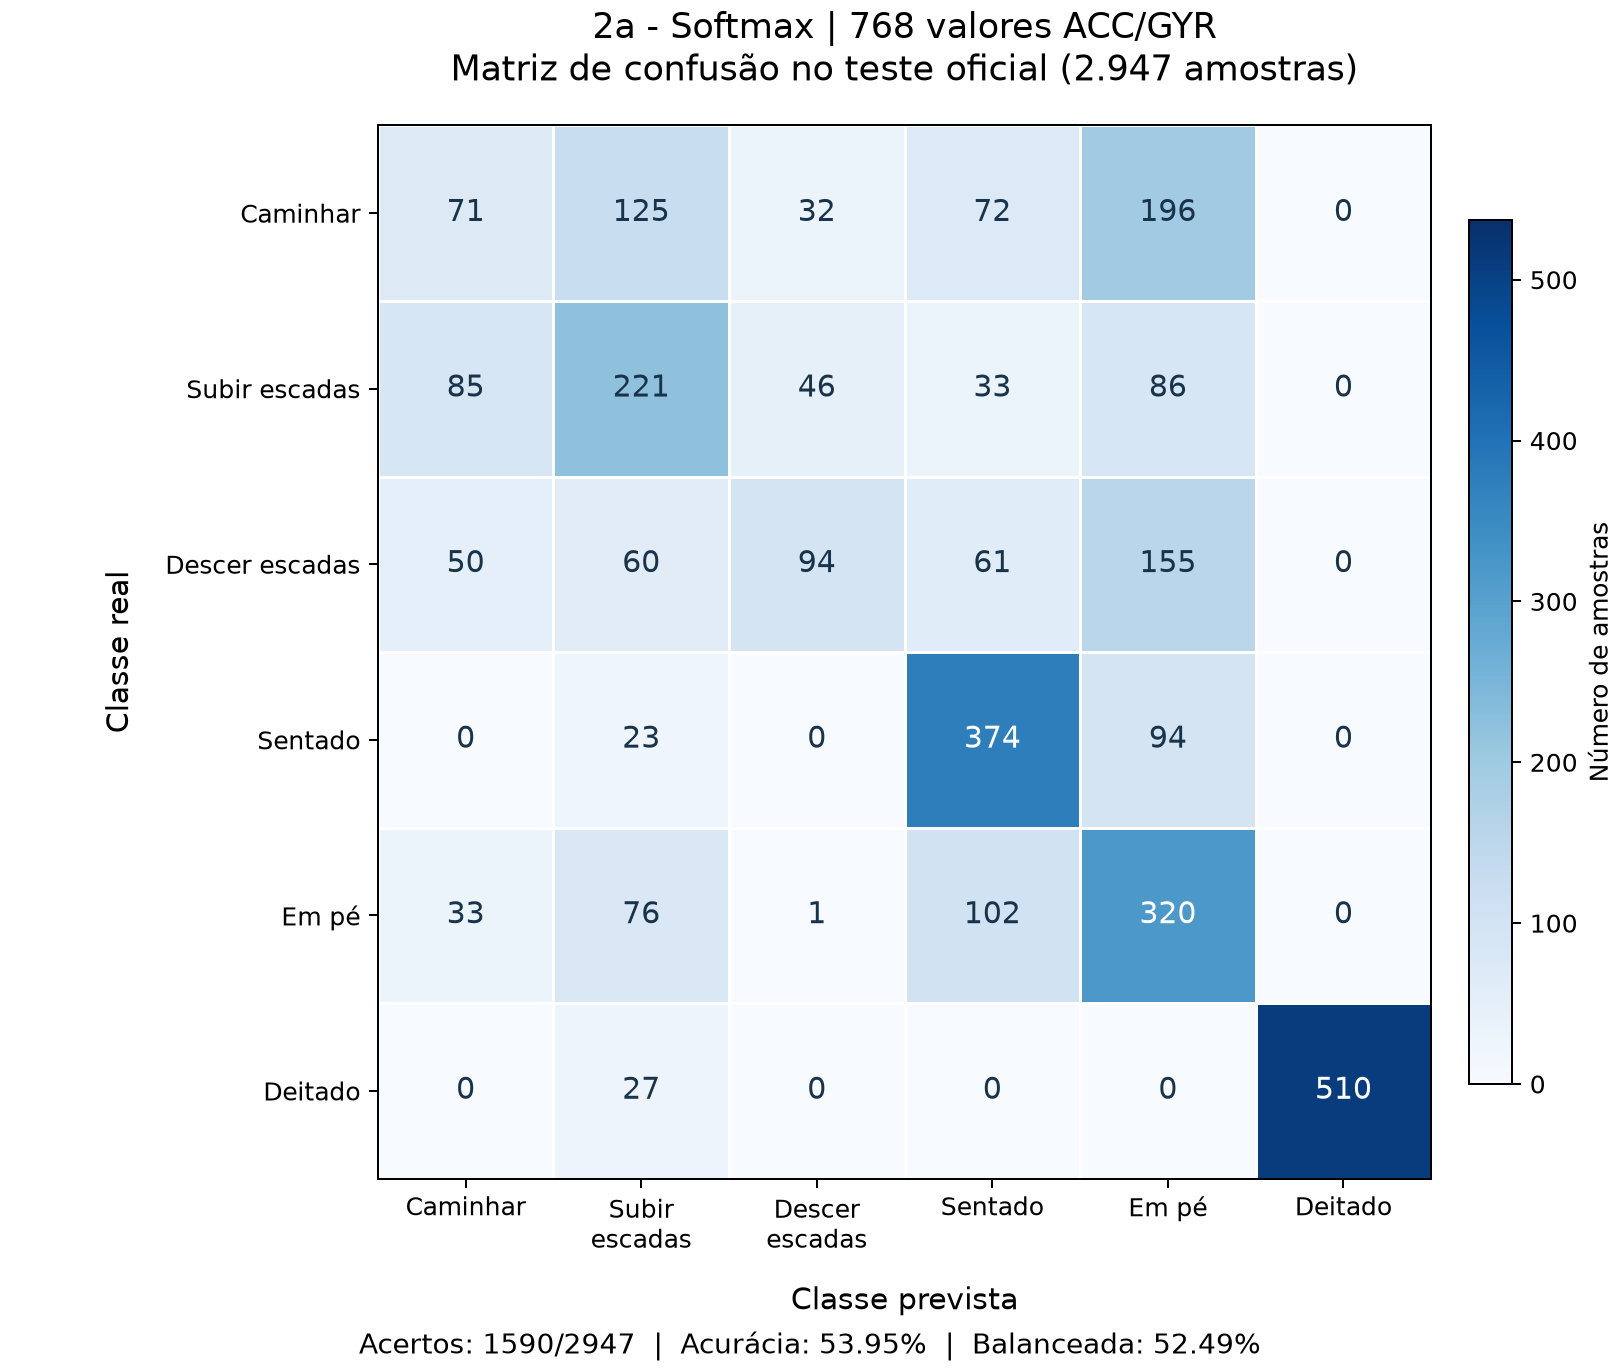

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Linhas: classes reais. Colunas: classes previstas. Valores absolutos.
rotulos = ["Caminhar", "Subir\nescadas", "Descer\nescadas", "Sentado", "Em pé", "Deitado"]
matriz = np.asarray(matriz_confusao_teste, dtype=int)
fig, ax = plt.subplots(figsize=(9, 7.6), layout="constrained")
imagem = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=537)
barra = fig.colorbar(imagem, ax=ax, shrink=0.82, pad=0.03)
barra.set_label("Número de amostras")
ax.set_xticks(range(6), labels=rotulos)
ax.set_yticks(range(6), labels=[r.replace("\n", " ") for r in rotulos])
ax.set_xlabel("Classe prevista", fontsize=12, labelpad=12)
ax.set_ylabel("Classe real", fontsize=12, labelpad=12)
ax.set_title("2a - Softmax | 768 valores ACC/GYR\nMatriz de confusão no teste oficial (2.947 amostras)", fontsize=14, pad=18)
for i in range(6):
    for j in range(6):
        ax.text(j, i, str(matriz[i, j]), ha="center", va="center",
                fontsize=12, color="white" if matriz[i, j] > 537 / 2 else "#18334A")
ax.set_xticks(np.arange(-0.5, 6, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 6, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.2)
ax.tick_params(which="minor", bottom=False, left=False)
acertos = int(np.trace(matriz))
fig.supxlabel(
    f"Acertos: {acertos}/2947  |  Acurácia: {100 * metricas_finais['acuracia_teste']:.2f}%"
    f"  |  Balanceada: {100 * metricas_finais['acuracia_balanceada_teste']:.2f}%", fontsize=11,
)
pasta_figuras = project_root / "results" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)
fig.savefig(pasta_figuras / "confusao_2a.png", dpi=180, facecolor="white")
plt.show()
